# CMLC/GMLP SAOCOM demo

In [1]:
"""
File Name: mlc_SAOCOM.ipynb

Author:
    Francesco De Zan
    delta phi remote sensing GmbH

Date: October 2025

Description:
------------
This script performs the generation of CMLC and GMLP for a stack of CSLCs from the SAOCOM sensor. 
Options and configuration parameters about some processing steps can be set
by the user.

Usage:
------
To use this script, define the following parameters:
    
    - cslc_file_name
    - cmlc_file_name
    - gmlc_file_name

Optionally, set the processing parameters:
    - w_rg: the range extension of the multi-looking window
    - w_az: the azimuth extension of the multi-looking window
    - subsampling: the sub-sampling factor for the GMLP compared to a 10 m x 10 m grid
    - mini_size: the number of acquisitions contributing to the generation of the "past references"
    - memory_param: the autoregression parameter for the reference update (0 => totally forgetting the past)
    - coherence_threshold: the threshold to calibrate current reference with a past reference (below that, skip calibration)

"""

'\nFile Name: mlc_SAOCOM.ipynb\n\nAuthor:\n    Francesco De Zan\n    delta phi remote sensing GmbH\n\nDate: October 2025\n\nDescription:\n------------\nThis script performs the generation of CMLC and GMLP for a stack of CSLCs from the SAOCOM sensor. \nOptions and configuration parameters about some processing steps can be set\nby the user.\n\nUsage:\n------\nTo use this script, define the following parameters:\n    \n    - cslc_file_name\n    - cmlc_file_name\n    - gmlc_file_name\n\nOptionally, set the processing parameters:\n    - w_rg: the range extension of the multi-looking window\n    - w_az: the azimuth extension of the multi-looking window\n    - subsampling: the sub-sampling factor for the GMLP compared to a 10 m x 10 m grid\n    - mini_size: the number of acquisitions contributing to the generation of the "past references"\n    - memory_param: the autoregression parameter for the reference update (0 => totally forgetting the past)\n    - coherence_threshold: the threshold to 

In [ ]:
## I/O configuration

#base_dir = "/media/data/SAR/L2/Naples/ASC/S4/"
#base_dir = "/media/data/SAR/L2/Naples/DSC/S3/"
base_dir = "/media/data/SAR/L2/Naples/DSC/S4/"

#channel_dir = "slcs.zarr"
#channel_dir = "SAOCOM_DSC_S3_20250212_POLARIZATION_VV/"
channel_dir = "SAOCOM_DSC_S4_20250220_POLARIZATION_VV/"

# input cslc product
cslc_file_name = base_dir + channel_dir

# output cmlc product
cmlc_file_name = base_dir +"cmlcs_many_pasts.zarr"

# output gmlc product
gmlc_file_name = cmlc_file_name + ".gmlc"

In [ ]:
## Processing parameter configuration

# selecting window sizes (rg, az) and mini_size (number of acquisitions after which the long-term calibration kicks-in)
w_rg = 10
w_az = 20
multilook = {"azimuth_time": w_az, "slant_range_time": w_rg}

# subsampling for geocoding: default is sampled @ 10m x 10m, we want 50m x 50m
subsampling = 5

#mini_size = 100 # this setting disables the long-term calibration, since 100 > N
mini_size = 10
mini_size = 10

memory_param = 0.95 # autoregression parameter for the reference update (0 => totally forgetting the past)

#memory_param_past = 1.0 # autoregression parameter for the past reference update (0 => totally forgetting the past)
#memory_param_ma = 0.0 # moving average parameter for the past reference update (0 => freezing past reference)

coherence_threshold = 0.1 # threshold to calibrate current reference with a past reference (below that, skip calibration)

In [4]:
import numpy as np
import datatree
import xarray as xr
import matplotlib.pyplot as plt
from tqdm import tqdm
import shutil

In [5]:
import rosel.io
import rosel.computation
import rosel.shiroma

In [6]:
type, n_jobs, job_memory = ["LOCAL", 16, None]
client = rosel.computation.create_client(type, n_jobs, job_memory)

2026-03-06 13:55:37 [debug    ] <Cluster info: type=LOCAL, n_jobs=16, job_memory=3997783372>


In [7]:
# opening the CSLC dataset
ds = datatree.open_datatree(cslc_file_name, engine='zarr', chunks={})

cstack = ds.coreg.cstack
N = len(cstack)

In [8]:
# initialization for full-scene version
n_lines, n_samples = cstack[0].shape
n_rg = np.floor_divide(n_samples, w_rg)
n_az = np.floor_divide(n_lines, w_az)
#n_rg = 100
#n_az = 400


interf = xr.DataArray(np.zeros([N, n_az, n_rg], dtype=np.complex64),dims=["acquisition_date","azimuth_time","slant_range_time"])
est_phase_complex = xr.DataArray(np.zeros([n_az, n_rg], dtype=np.complex64),dims=["azimuth_time","slant_range_time"])
corr_phase = xr.DataArray(np.zeros([n_az, n_rg], dtype=np.complex64),dims=["azimuth_time","slant_range_time"])
corr_phase_ = xr.DataArray(np.zeros([n_az, n_rg], dtype=np.complex64),dims=["azimuth_time","slant_range_time"])

short_term_coherence = xr.DataArray(np.zeros([N, n_az, n_rg])*np.nan,dims=["acquisition_date","azimuth_time","slant_range_time"])
long_term_coherence = xr.DataArray(np.zeros([N, n_az, n_rg])*np.nan,dims=["acquisition_date","azimuth_time","slant_range_time"])

In [9]:
def make_interf_(A, B):
    return (A.conj() * B).coarsen(azimuth_time=w_az, slant_range_time=w_rg, boundary='trim').mean()

def make_coh_(A, B):
    return make_interf_(A,B) / (np.sqrt(make_interf_(A,A) * make_interf_(B,B))).fillna(1)

In [10]:
# allocating arrays for the references
N_past_ref_max = N // mini_size # total number of past references
current_reference = xr.DataArray(cstack[0][0:w_az*n_az,0:w_rg*n_rg].values, dims=["azimuth_time","slant_range_time"])
past_references = xr.DataArray(np.zeros([N_past_ref_max, w_az*n_az,w_rg*n_rg], dtype=np.complex64), dims=["t", "azimuth_time","slant_range_time"])

In [11]:
# main algorithm (progressive interferometric phase estimation)
# full-scene version
# optimized version

slc = xr.DataArray(np.zeros_like(current_reference), dims=["azimuth_time","slant_range_time"])

step = 0
n_past_ref = 0 # currently valid past references

for n in tqdm(range(0,N,1)):
#for n in tqdm(range(0,30,1)):

    step = step + 1
    #print(step)
    slc = cstack[n][0:w_az*n_az,0:w_rg*n_rg] # getting the current slc
    
    # compute new interferogram
    interf[n,:,:] = make_coh_(current_reference, slc).data
    short_term_coherence[n,:,:] = abs(interf[n,:,:])

    # normalize interferogram to phasor
    est_phase_complex[:] = interf[n,:,:] / (np.abs(interf[n,:,:]).fillna(1).where(np.abs(interf[n,:,:] != 0),1))
    
    # update the current reference
    temp = slc.coarsen(azimuth_time=w_az, slant_range_time=w_rg, boundary='trim').construct(
        azimuth_time=("az_coarse", "az_window"), slant_range_time=("rg_coarse", "rg_window"), keep_attrs=True)
    temp = temp*est_phase_complex.rename({'azimuth_time':'az_coarse','slant_range_time':'rg_coarse'}).conj()
    temp = temp.stack(azimuth_time=('az_coarse', 'az_window'), slant_range_time=('rg_coarse','rg_window'))
    current_reference[:] = current_reference*memory_param + temp.fillna(0)
        
    # generate (a) the past reference
    if step % mini_size == 0:
        #print("New past_reference")
        past_references[n_past_ref,:,:] = current_reference[:,:]
            
    # long-term phase calibration of current_reference
    if n_past_ref > 0 :
        #print("Calibration of current_reference")
        corr_phase[:] = 1
        for p in range(n_past_ref-1,-1,-1) : # we start from the newest and move to the oldest - not the most efficient strategy
            corr_phase_[:] = make_coh_(past_references[p],current_reference)
            mask = (np.abs(corr_phase_) >= coherence_threshold)[:]
            corr_phase.data[mask] = corr_phase_.data[mask]

        long_term_coherence[n,:,:] = np.abs(make_coh_(past_references[0],current_reference))    
        corr_phase[:] = corr_phase/np.abs(corr_phase)
        
        temp = current_reference.coarsen(azimuth_time=w_az, slant_range_time=w_rg, boundary='trim').construct(
            azimuth_time=("az_coarse", "az_window"), slant_range_time=("rg_coarse", "rg_window"), keep_attrs=True)
        temp = temp*corr_phase.rename({'azimuth_time':'az_coarse','slant_range_time':'rg_coarse'}).fillna(1).conj()
        temp = temp.stack(azimuth_time=('az_coarse', 'az_window'), slant_range_time=('rg_coarse','rg_window'))
    
        current_reference[:] = temp
        #long_term_coherence[n,:,:] = np.abs(make_coh_(past_references[0],slc))
        #past_reference [:] = past_reference [:] * memory_param_past + current_reference[:].fillna(0) * memory_param_ma

    if step % mini_size == 0:
        n_past_ref += 1 

  0%|          | 0/67 [00:00<?, ?it/s]/home/francesco/miniconda3/envs/rosel/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))
/home/francesco/miniconda3/envs/rosel/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))
/home/francesco/miniconda3/envs/rosel/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))
/home/francesco/miniconda3/envs/rosel/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))
/home/francesco/miniconda3/envs/rosel/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args

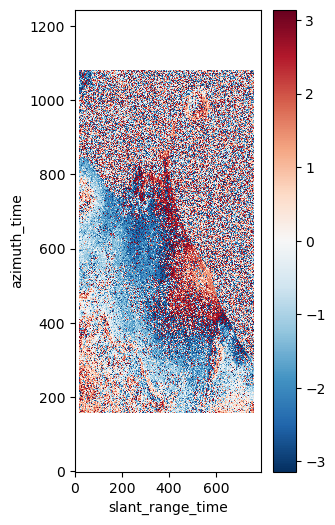

In [16]:
plt.figure(figsize=(3,6))
phase = xr.apply_ufunc(np.angle, interf[23][:,:]*np.conj(interf[25][:,:]), dask='parallelized')
phase.plot()

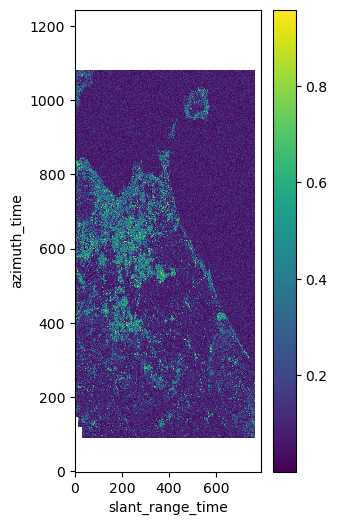

In [17]:
coh = make_coh_(past_references[0,:,:],current_reference)
coh = xr.apply_ufunc(np.abs, coh, dask='parallelized')
plt.figure(figsize=(3,6))
coh.plot()

In [12]:
# collecting and formatting output
attrs = cstack.attrs
attrs['multilook'] = multilook

cmlc_ds = xr.Dataset(
    data_vars=dict(
        phase=(["acquisition_date", "azimuth_time", "slant_range_time"], interf.data),
        long_term_coherence=(["acquisition_date", "azimuth_time", "slant_range_time"], long_term_coherence.data),
        short_term_coherence=(["acquisition_date", "azimuth_time", "slant_range_time"], short_term_coherence.data),
    ),

    coords=dict(
        azimuth_time=("azimuth_time", cstack[0].azimuth_time.coarsen(azimuth_time=w_az, boundary='trim').mean().data),
        slant_range_time=("slant_range_time", cstack[0].slant_range_time.coarsen(slant_range_time=w_rg, boundary='trim').mean().data),
        acquisition_date=("acquisition_date", cstack.acquisition_date.data),
    ),

    #attrs=dict(description="Co-registered Multi-look Complex"),
    attrs=attrs,
    
)

In [13]:
#saving
cmlc_ds.to_zarr(cmlc_file_name)

In [ ]:
# loading CMLC
ds_cmlc = datatree.open_datatree(cmlc_file_name, engine='zarr', chunks={})

In [ ]:
selection_path = f"{base_dir}/SHIROMA/selection"
global_values_path = f"{base_dir}/SHIROMA/global_values"
rtc_ap_path = f"{base_dir}/SHIROMA/rtc_ap"

In [ ]:
selection = rosel.io.read(selection_path)

In [ ]:
# "g" has lost 1 pixel compared to "selection"!
nx = np.floor_divide(selection.dims['x']-1, subsampling)
ny = np.floor_divide(selection.dims['y']-1, subsampling)
phase                   = xr.DataArray(np.zeros([N, nx, ny], dtype=np.float64),dims=["acquisition_date","x","y"])
long_term_coherence     = xr.DataArray(np.zeros([N, nx, ny], dtype=np.float64),dims=["acquisition_date","x","y"])
short_term_coherence    = xr.DataArray(np.zeros([N, nx, ny], dtype=np.float64),dims=["acquisition_date","x","y"])

In [ ]:
def geocode_3D(cmlc_input, gmlc_output, f):

    for n in tqdm(range(0,N)):
        # save CMLC (temp)
        cmlc_temp_file_name = f"{base_dir}/SHIROMA/cmlc_temp"
        try:
            shutil.rmtree(cmlc_temp_file_name)
        except OSError as e:
            print("Error: %s - %s." % (e.filename, e.strerror))
    
        cmlc = cmlc_input[n] # ds_cmlc.phase[n]
        cmlc = np.pad(cmlc.data, pad_width=((0,1),(0,1))) # these should be computed! padding is assumed!
        cmlc = xr.DataArray(cmlc, dims=['azimuth_time', 'slant_range_time'], name='v').chunk(azimuth_time=300, slant_range_time=300)
    
        cmlc = xr.Dataset(
            data_vars=dict(
                v=(["azimuth_time", "slant_range_time"], cmlc.data),
            ),
            coords=dict(
                azimuth_time=("azimuth_time", cstack[0].azimuth_time.coarsen(azimuth_time=w_az, boundary='pad').mean().data),
                slant_range_time=("slant_range_time", cstack[0].slant_range_time.coarsen(slant_range_time=w_rg, boundary='pad').mean().data),
            ),
            attrs=dict(description="Co-registered Multi-look Complex"),
        )
    
        rosel.io.write(cmlc, cmlc_temp_file_name)

        # generate and save GMLP (temp)
        gmlc_temp_file_name = f"{base_dir}/SHIROMA/gmlc_temp"
        try:
            shutil.rmtree(gmlc_temp_file_name)
        except OSError as e:
            print("Error: %s - %s." % (e.filename, e.strerror))
    
        g = rosel.shiroma.map_geo_ap(
            c_path=cmlc_temp_file_name,
            simulation=selection,
            data_path_shiroma=f"{base_dir}/SHIROMA/",
            data_path_geo_ap=gmlc_temp_file_name,
            multilook=multilook,
            read=True,
            enable_dask=True,
        )
        # subsample (to 50 m sampling)
        g_coarse = g.coarsen(x=subsampling, y=subsampling, boundary='trim').mean()
        gmlc_output[n,:,:] = xr.apply_ufunc(f, g_coarse, dask='parallelized').chunk(dict(x=50,y=50))
    

In [ ]:
## geocoding for each acquisition date
## directly from CMLC product without oversampling
geocode_3D(ds_cmlc.phase, phase, np.angle)
geocode_3D(ds_cmlc.long_term_coherence, long_term_coherence, np.abs)
geocode_3D(ds_cmlc.short_term_coherence, short_term_coherence, np.abs)

In [ ]:
# substituting 0's with NaN's
phase[1:,:,:] = phase[1:,:,:].where(phase[1:,:,:] != 0, np.NaN)
long_term_coherence = long_term_coherence.where(long_term_coherence != 0, np.NaN)
short_term_coherence = short_term_coherence.where(short_term_coherence != 0, np.NaN)

In [ ]:
attrs = cstack.attrs
attrs['multilook'] = multilook

# collecting and formatting output
gmlc_ds = xr.Dataset(
    data_vars=dict(
        phase=(["acquisition_date", "x", "y"], np.float32(phase.data)),
        long_term_coherence=(["acquisition_date", "x", "y"], np.float16(long_term_coherence.data)),
        short_term_coherence=(["acquisition_date", "x", "y"], np.float16(short_term_coherence.data)),
    ),

    coords=dict(
        x=("x", selection.x.coarsen(x=subsampling, boundary='trim').mean().data[0:-1]),
        y=("y", selection.y.coarsen(y=subsampling, boundary='trim').mean().data),
        acquisition_date=("acquisition_date", cstack.acquisition_date.data),
    ),

    #attrs=dict(description="Geocoded Multi-look Complex"),
    attrs = attrs
)

In [ ]:
gmlc_ds = gmlc_ds.transpose('acquisition_date', 'y', 'x')

In [ ]:
gmlc_ds.to_zarr(gmlc_file_name)